# 03 · Data Cleaning and Preparation
**Milestone 2 — Kenyan Retail Customer & Sales Intelligence Capstone**

**Goal:** turn the raw extracts in `data/raw/` into trustworthy, validated tables, and record every decision.

| Step | What we do |
|---|---|
| 1 | Inspect the tables: shape, types, summary statistics |
| 2 | Profile data quality *before* cleaning |
| 3 | Remove duplicates |
| 4 | Fix data types (dates, amounts stored as text) |
| 5 | Standardize inconsistent labels |
| 6 | Handle missing values (recover from evidence, or flag) |
| 7 | Investigate outliers and value errors |
| 8 | Recalculate revenue, discount, cost and profit |
| 9 | Clean the dimension tables and validate primary and foreign keys |
| 10 | Engineer analytical features |
| 11 | Validate, compare before and after, save |
| 12 | Audit against the injection log |

**Rules followed:** nothing is deleted or filled in silently. Missing values are recovered only from evidence inside the
data. Raw files are never overwritten.

All cleaning logic lives in `src/preprocessing/cleaning.py`. This notebook calls those functions one step at a time
and explains each one.

In [1]:
# --- Setup: make the project's "src" package importable from this notebook ---
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.visualization import style

style.apply_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
from src.preprocessing import cleaning as cl
from src.preprocessing.pipeline import load_raw, clean_dimensions, SALES_COLUMNS
from src.preprocessing.features import build_analytical_dataset

raw = load_raw()
raw_sales = raw["sales_transactions"]
print({name: df.shape for name, df in raw.items()})

{'sales_transactions': (3000, 16), 'customers': (1800, 7), 'products': (40, 7), 'stores': (6, 7), 'promotions': (20, 7), 'calendar': (731, 14)}


## 1. Inspect the raw sales table

In [3]:
raw_sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_id       3000 non-null   str    
 1   order_id             3000 non-null   str    
 2   transaction_date     3000 non-null   str    
 3   transaction_time     3000 non-null   str    
 4   customer_id          2975 non-null   str    
 5   store_id             3000 non-null   str    
 6   product_id           3000 non-null   str    
 7   quantity             3000 non-null   int64  
 8   unit_price           3000 non-null   float64
 9   unit_cost            3000 non-null   float64
 10  discount_percentage  3000 non-null   float64
 11  discount_amount      3000 non-null   float64
 12  total_amount         3000 non-null   str    
 13  profit               3000 non-null   float64
 14  payment_method       2990 non-null   str    
 15  promotion_id         316 non-null    str    
dtyp

`info()` already shows two **type problems**:
- `transaction_date` is text (`str`), as expected for a raw CSV, but some values may not be in ISO format.
- `total_amount` is **text**, although it should be numeric. Some values must contain non-numeric characters.

The two "missing" columns, `customer_id` (2,975 of 3,000 filled) and `payment_method` (2,990), need investigating.
`promotion_id` is mostly blank **by design**: a blank simply means the line was not on promotion.

In [4]:
raw_sales.describe().T

,count,mean,std,min,25%,50%,75%,max
quantity,"3,000.00",2.93,36.44,1.00,1.00,1.00,2.00,999.00
unit_price,"3,000.00",605.16,"1,240.99",65.00,185.00,260.00,541.00,"22,880.00"
unit_cost,"3,000.00",438.69,937.11,55.00,155.00,202.80,420.00,"19,136.00"
discount_percentage,"3,000.00",1.39,4.13,0.00,0.00,0.00,0.00,20.00
discount_amount,"3,000.00",14.57,72.07,0.00,0.00,0.00,0.00,"1,280.00"
profit,"3,000.00",188.99,502.74,-80.00,41.20,67.36,139.20,"21,632.00"


`describe()` shows that the **maximum quantity is 999**, while the 75th percentile is only 2.
Values this extreme need a closer look (Step 7). `unit_price` ranges from KES 65 (milk) to tens of thousands
(TVs), which is plausible because the product mix is wide.

## 2. Data-quality profile before cleaning

In [5]:
before = cl.sales_quality_profile(raw_sales)
before.to_frame("raw (before)")

,raw (before)
rows,3000
exact_duplicate_rows,12
duplicate_transaction_ids,12
missing_customer_id,25
missing_payment_method,10
non_standard_payment_labels,30
dates_not_in_iso_format,15
total_amount_not_numeric,10
rows_failing_reconciliation,10
quantity_above_100,4


In [6]:
# Show examples of each kind of problem found
examples = {
    "Non-ISO dates": raw_sales.loc[pd.to_datetime(raw_sales["transaction_date"], format="%Y-%m-%d",
                                                  errors="coerce").isna(), "transaction_date"].head(3).tolist(),
    "Non-numeric totals": raw_sales.loc[pd.to_numeric(raw_sales["total_amount"], errors="coerce").isna(),
                                        "total_amount"].head(3).tolist(),
    "Payment labels": sorted(raw_sales["payment_method"].dropna().unique().tolist()),
}
for k, v in examples.items():
    print(f"{k}: {v}")

Non-ISO dates: ['06/01/2024', '15/03/2024', '03/04/2024']
Non-numeric totals: ['KES 280.00', 'KES 1,700.00', 'KES 80.00']
Payment labels: [' Cash', 'Bank', 'Bank Transfer', 'CASH ', 'Cash', 'Debit/Credit Card', 'M-PESA', 'M-Pesa', 'MPESA', 'card', 'cash', 'credit card', 'm-pesa ', 'mpesa']


The profile confirms seven kinds of problem in the sales table:
1. duplicate rows;
2. missing customer IDs;
3. missing payment methods;
4. non-standard payment labels (`mpesa`, `CASH `, `credit card`, …);
5. dates in `DD/MM/YYYY` format;
6. totals stored as text (`KES 1,234.00`);
7. rows where the total does not match quantity × price − discount.

## 3. Duplicates

Two kinds of duplicate are possible:
- **Exact duplicates:** every column is identical. This is a receipt submitted twice, so it is safe to remove.
- **Duplicate `transaction_id` with different values:** this would be a real conflict that needs investigation.

In [7]:
exact_dups = raw_sales[raw_sales.duplicated(keep=False)].sort_values("transaction_id")
print(f"Rows involved in exact duplication: {len(exact_dups)} ({raw_sales.duplicated().sum()} surplus copies)")
display(exact_dups.head(6))

sales = raw_sales.drop_duplicates().reset_index(drop=True)
print(f"Rows after removing exact duplicates: {len(sales):,}")
print(f"Duplicate transaction_ids remaining: {sales['transaction_id'].duplicated().sum()}")

Rows involved in exact duplication: 24 (12 surplus copies)


,transaction_id,order_id,transaction_date,transaction_time,customer_id,store_id,product_id,quantity,unit_price,unit_cost,discount_percentage,discount_amount,total_amount,profit,payment_method,promotion_id
119,TXN00120,ORD00108,2024-02-10,18:01,C0661,S04,P035,1,"1,500.00",850.00,0.00,0.00,1500.0,650.00,Cash,NaN
120,TXN00120,ORD00108,2024-02-10,18:01,C0661,S04,P035,1,"1,500.00",850.00,0.00,0.00,1500.0,650.00,Cash,NaN
849,TXN00849,ORD00754,2024-08-11,16:37,C1084,S04,P002,1,195.00,170.00,0.00,0.00,195.0,25.00,M-Pesa,NaN
850,TXN00849,ORD00754,2024-08-11,16:37,C1084,S04,P002,1,195.00,170.00,0.00,0.00,195.0,25.00,M-Pesa,NaN
857,TXN00856,ORD00761,2024-08-13,17:57,C0716,S01,P033,1,"1,800.00","1,050.00",0.00,0.00,1800.0,750.00,M-Pesa,NaN
858,TXN00856,ORD00761,2024-08-13,17:57,C0716,S01,P033,1,"1,800.00","1,050.00",0.00,0.00,1800.0,750.00,M-Pesa,NaN


Rows after removing exact duplicates: 2,988
Duplicate transaction_ids remaining: 0


**Decision:** remove the 12 surplus copies, keeping the first occurrence. After removal, no transaction ID is repeated,
so there were no *conflicting* duplicates. `transaction_id` is now a valid primary key. **2,988 rows remain.**

## 4. Fix data types

In [8]:
# Dates: parse the two formats EXPLICITLY. Letting pandas guess could swap day and month
# (is 03/04/2024 the 3rd of April or the 4th of March?). The DD/MM variant comes from one till export.
sales["transaction_date"] = cl.parse_mixed_dates(sales["transaction_date"])

# Amounts: strip the "KES" prefix and thousands separators, then convert to numbers.
sales["total_amount"] = cl.parse_amount(sales["total_amount"])

print(sales[["transaction_date", "total_amount"]].dtypes.to_string())
print("Date range:", sales["transaction_date"].min().date(), "to", sales["transaction_date"].max().date())

transaction_date    datetime64[us]
total_amount               float64
Date range: 2024-01-01 to 2025-12-31


All 2,988 dates parsed, and they all fall inside the study period (2024-01-01 to 2025-12-31). An unparseable value
would have raised an error rather than becoming a silent blank. `total_amount` is now numeric.

## 5. Standardize labels

In [9]:
before_labels = sales["payment_method"].value_counts(dropna=False)
sales["payment_method"] = cl.standardise_payment(sales["payment_method"])
after_labels = sales["payment_method"].value_counts(dropna=False)
pd.concat([before_labels.rename("before"), after_labels.rename("after")], axis=1).fillna(0).astype(int)

,before,after
payment_method,,
M-Pesa,1628,1647
Cash,693,699
Debit/Credit Card,472,476
Bank Transfer,155,156
NaN,10,10
M-PESA,7,0
mpesa,6,0
m-pesa,4,0
CASH,4,0


**Decision:** each spelling was mapped to one of the four official payment methods using an explicit lookup table
(`PAYMENT_MAP`), not fuzzy matching. That way every mapping can be reviewed, and an unknown new spelling stops the
pipeline instead of being guessed. The 10 blanks are handled in the next step.

## 6. Missing values

| Column | Blanks | Why it matters |
|---|---|---|
| `payment_method` | 10 | Payment-mix analysis |
| `customer_id` | 25 | Customer analytics (RFM, cohorts, churn) |
| `promotion_id` | ~2,670 | **Not missing**: blank means "no promotion" |

**Evidence-based recovery:** payment method and customer are captured **once per receipt**, so every line of an order
must share them. If another line of the same `order_id` has the value, we can recover it with certainty.
Anything that cannot be recovered is **not guessed**.

In [10]:
sales, n_pay = cl.fill_from_same_order(sales, "payment_method")
print(f"payment_method recovered from the same order: {n_pay}")
print(f"payment_method still blank -> set to 'Unknown': {sales['payment_method'].isna().sum()}")
sales["payment_method"] = sales["payment_method"].fillna("Unknown")

sales, n_cust = cl.fill_from_same_order(sales, "customer_id")
sales["is_walk_in"] = sales["customer_id"].isna()
print(f"customer_id recovered from the same order: {n_cust}")
print(f"customer_id still blank -> kept blank, flagged is_walk_in: {sales['is_walk_in'].sum()}")

payment_method recovered from the same order: 3
payment_method still blank -> set to 'Unknown': 7


customer_id recovered from the same order: 4
customer_id still blank -> kept blank, flagged is_walk_in: 21


**Decisions:**
- **Payment method:** 3 recovered from the same receipt. The remaining 7 become `"Unknown"`. Imputing the most common
  method (M-Pesa) would inflate M-Pesa's share with made-up data. 7 of 2,988 lines (0.2%) is too few to affect any conclusion.
- **Customer ID:** 4 recovered from the same receipt. The remaining 21 lines (0.7%) are **kept** for revenue, store and
  product analysis, because the sale really happened. They are flagged `is_walk_in` and excluded from customer-level
  analysis (RFM, cohorts, churn). Deleting them would understate revenue, and assigning them to a random customer
  would corrupt the customer histories.

## 7. Outliers and value errors

An outlier is a value that is unusually far from the others. It can be a **mistake** (fix it) or a **real but rare
event** (keep it). We investigate each one before deciding.

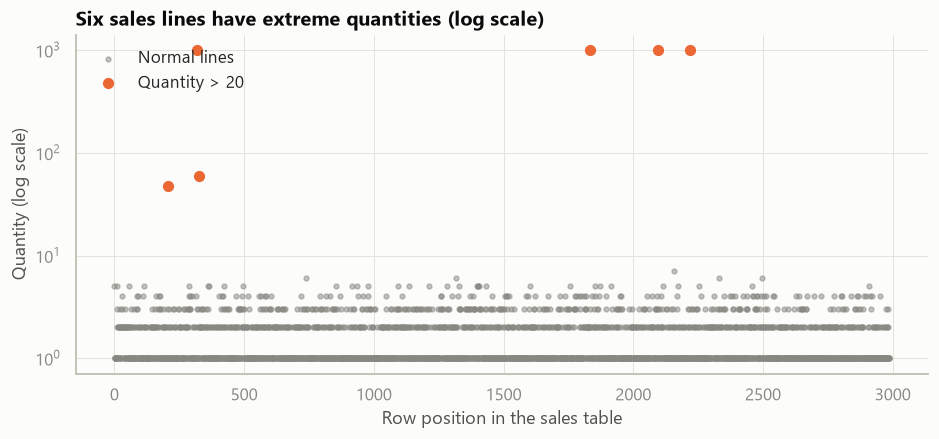

,transaction_id,product_id,quantity,unit_price,discount_percentage,total_amount,implied_quantity,product_name
0,TXN00208,P004,48,330.00,0.00,"15,840.00",48.00,White Sugar
1,TXN00320,P018,999,380.00,0.00,380.00,1.00,Laundry Detergent
2,TXN00328,P011,60,80.00,12.00,"4,224.00",60.00,Bottled Water
3,TXN01834,P013,999,260.00,0.00,260.00,1.00,Mango Juice
4,TXN02095,P009,999,333.00,0.00,333.00,1.00,Black Tea Leaves
5,TXN02219,P021,999,468.00,0.00,468.00,1.00,Toilet Paper


In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
qty = sales["quantity"]
ax.scatter(range(len(qty)), qty, s=10, color=style.NEUTRAL, alpha=0.5, label="Normal lines")
big = qty > 20
ax.scatter(qty.index[big], qty[big], s=40, color=style.SERIES[1], label="Quantity > 20", zorder=3)
ax.set_yscale("log")
ax.set_title("Six sales lines have extreme quantities (log scale)")
ax.set_xlabel("Row position in the sales table")
ax.set_ylabel("Quantity (log scale)")
ax.legend(loc="upper left")
style.save(fig, "m2_quantity_outliers")
plt.show()

# Does each extreme quantity reconcile with the recorded total?
extreme = sales.loc[big, ["transaction_id", "product_id", "quantity", "unit_price",
                          "discount_percentage", "total_amount"]].copy()
extreme["implied_quantity"] = (extreme["total_amount"] /
                               (extreme["unit_price"] * (1 - extreme["discount_percentage"] / 100))).round(2)
extreme.merge(raw["products"][["product_id", "product_name"]], on="product_id")

**Interpretation:** six lines stand out, but they fall into two different groups:
- **Four lines with quantity 999:** the recorded total implies exactly **1 unit** in every case. The receipt total and the quantity
  contradict each other. A 999 is a classic keying error (holding down a key), so the quantity is wrong and the total is right.
- **Two lines with 60 bottled waters and 48 bags of sugar:** the total matches the quantity exactly. These are
  **genuine bulk purchases**, for example a school or church event.

**Decision:** restore the four 999s to the quantity implied by the total. **Keep** the two bulk purchases, because
deleting real sales would understate revenue. They stay in the data and can be filtered in analysis if they distort averages.

**Business implication:** if the 999s had been left in, they would have added about **KES 1.44 million** of phantom revenue (998 extra units × four
prices). That is roughly two-thirds of the chain's real two-year revenue, and it would have wrecked any demand forecast.

In [12]:
sales, qty_report = cl.fix_quantity_entry_errors(sales)
qty_report

,transaction_id,product_id,quantity,total_amount,implied_quantity
319,TXN00320,P018,999,380.00,1
1833,TXN01834,P013,999,260.00,1
2094,TXN02095,P009,999,333.00,1
2218,TXN02219,P021,999,468.00,1


### 7.1 Unit-price check against the shelf price

A wrong price can be internally consistent (the till multiplies the wrong price correctly), so reconciliation alone
will not catch it. Instead, each line's price is compared with the **most common price for that product in that
year**: the observed shelf price. Prices change on 1 January 2025, so the comparison is made per year.

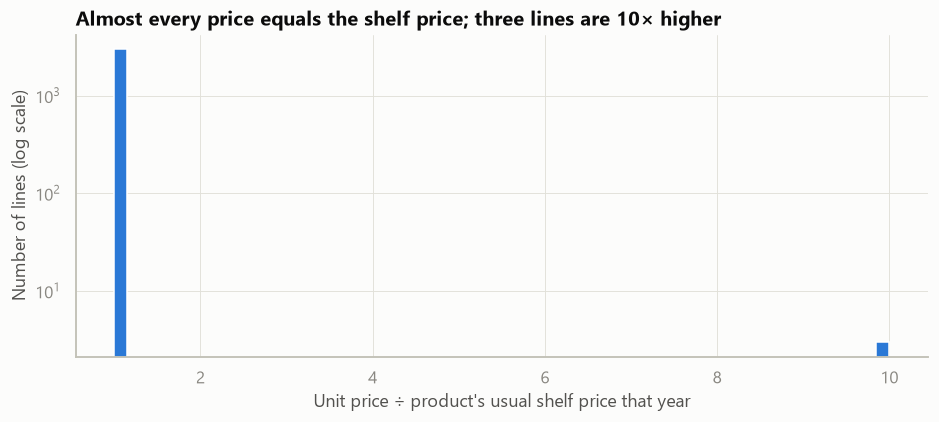

,transaction_id,product_id,unit_price,shelf_price,ratio,product_name
0,TXN00657,P028,"1,500.00",150.00,10.00,Sanitary Pads
1,TXN00705,P022,"1,800.00",180.00,10.00,Bleach
2,TXN01722,P034,"22,880.00","2,288.00",10.00,Denim Jeans


In [13]:
modal = cl.modal_price_by_product_year(sales)
keys = list(zip(sales["product_id"], sales["transaction_date"].dt.year))
ratio = sales["unit_price"].to_numpy() / np.array([modal[k] for k in keys])

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(ratio, bins=60, color=style.HIGHLIGHT)
ax.set_yscale("log")
ax.set_title("Almost every price equals the shelf price; three lines are 10× higher")
ax.set_xlabel("Unit price ÷ product's usual shelf price that year")
ax.set_ylabel("Number of lines (log scale)")
style.save(fig, "m2_price_ratio")
plt.show()

sales, price_report = cl.fix_price_typos(sales)
price_report.merge(raw["products"][["product_id", "product_name"]], on="product_id")

**Interpretation:** 2,985 lines are charged exactly the shelf price (ratio = 1). Three lines are charged **exactly 10×**
the shelf price: an extra zero typed at the till. Promotions are recorded separately as discounts, so a genuine price
difference this large has no business explanation.

**Decision:** replace these three prices with the shelf price. Their totals are recalculated in Step 8.

### 7.2 High-value orders: outliers, but genuine

Order values are naturally right-skewed, because a TV costs about 40 times as much as a bag of maize flour.
We check order values with the IQR rule (values above Q3 + 1.5 × IQR) to see *what* is driving them.

In [14]:
lines = sales.merge(raw["products"][["product_id", "category"]], on="product_id")
lines["category"] = cl.standardise_category(lines["category"])
q1, q3 = lines["total_amount"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
flagged = lines[lines["total_amount"] > upper]
print(f"IQR upper fence for line value: KES {upper:,.0f}; lines above it: {len(flagged)} ({len(flagged)/len(lines):.1%})")
flagged["category"].value_counts().to_frame("lines_above_fence")

IQR upper fence for line value: KES 1,532; lines above it: 356 (11.9%)


,lines_above_fence
category,
Clothing,220
Electronics,101
Food and Groceries,28
Personal Care,4
Household Products,2
Beverages,1


**Interpretation:** the lines above the IQR fence are almost all **electronics and clothing**, which are high-priced
categories. They are statistically "outliers" only because the distribution is skewed, not because they are wrong.

**Decision:** keep them. **Implication for later milestones:** skewed values call for medians, log scales and
non-parametric tests (Milestone 5), rather than means and t-tests alone.

## 8. Recalculate revenue, discounts, cost and profit

The derived money columns are recalculated from the base fields, so there is a single source of truth:

| Field | Formula |
|---|---|
| `gross_amount` | quantity × unit_price |
| `discount_amount` | gross_amount × discount_percentage / 100 |
| `total_amount` (net revenue) | gross_amount − discount_amount |
| `cost_amount` | quantity × unit_cost |
| `profit` | total_amount − cost_amount |

In [15]:
gap = cl.reconciliation_gap(sales)
mismatch = sales.loc[gap.abs() > 0.01, ["transaction_id", "quantity", "unit_price",
                                        "discount_percentage", "total_amount"]].copy()
mismatch["expected_total"] = (mismatch["quantity"] * mismatch["unit_price"]
                              * (1 - mismatch["discount_percentage"] / 100)).round(2)
mismatch["recorded_equals_gross"] = (mismatch["total_amount"] == mismatch["quantity"] * mismatch["unit_price"])
print(f"Lines whose recorded total does not reconcile: {len(mismatch)}")
mismatch

Lines whose recorded total does not reconcile: 9


,transaction_id,quantity,unit_price,discount_percentage,total_amount,expected_total,recorded_equals_gross
656,TXN00657,2,150.00,0.00,"3,000.00",300.00,False
696,TXN00697,2,520.00,15.00,"1,040.00",884.00,True
704,TXN00705,2,180.00,15.00,"3,060.00",306.00,False
1414,TXN01415,3,80.00,15.00,240.00,204.00,True
1721,TXN01722,1,"2,288.00",0.00,"22,880.00","2,288.00",False
1806,TXN01807,1,343.00,10.00,343.00,308.70,True
1808,TXN01809,2,343.00,10.00,686.00,617.40,True
1911,TXN01912,1,"1,872.00",15.00,"1,872.00","1,591.20",True
1914,TXN01915,1,884.00,15.00,884.00,751.40,True


**Interpretation:** nine lines do not reconcile.
- **Six** are promotion lines where the recorded total equals the *undiscounted* gross amount. The promotion and
  discount percentage were recorded, but the discount was never subtracted (a calculation bug).
- **Three** are the price-typo lines fixed in 7.1. Their old totals were based on the wrong price.

**Decision:** recalculate. For the six discount lines, the line carries a valid `promotion_id` and a discount
percentage that matches its campaign, so the formula is more trustworthy than the stored total.

In [16]:
sales = cl.recalculate_financials(sales)
print("Lines failing reconciliation after recalculation:", int((cl.reconciliation_gap(sales).abs() > 0.01).sum()))
print("Profit identity holds on every line:",
      bool(((sales["total_amount"] - sales["cost_amount"] - sales["profit"]).abs() <= 0.01).all()))
sales = sales[SALES_COLUMNS]

Lines failing reconciliation after recalculation: 0
Profit identity holds on every line: True


## 9. Clean the dimension tables and validate keys

In [17]:
print("Raw labels needing attention:")
print("  product categories:", sorted(raw["products"]["category"].unique()))
print("  store counties:    ", raw["stores"]["county"].tolist())
print("  customer genders:  ", raw["customers"]["gender"].value_counts().to_dict())

dims = clean_dimensions(raw)          # same standardisation functions as above
print("\nAfter cleaning:")
print("  product categories:", sorted(dims["products"]["category"].unique()))
print("  store counties:    ", dims["stores"]["county"].tolist())
print("  customer genders:  ", dims["customers"]["gender"].value_counts().to_dict())

Raw labels needing attention:
  product categories: ['Beverages', 'Clothing', 'Electronics', 'Food and Groceries', 'Household Products', 'Personal Care', 'Personal care ', 'food & groceries']
  store counties:     ['Nairobi', 'Nairobi', 'Kiambu', 'Mombasa', 'Kisumu', ' nakuru']
  customer genders:   {'Female': 967, 'Male': 825, 'F': 6, 'm': 2}

After cleaning:
  product categories: ['Beverages', 'Clothing', 'Electronics', 'Food and Groceries', 'Household Products', 'Personal Care']
  store counties:     ['Nairobi', 'Nairobi', 'Kiambu', 'Mombasa', 'Kisumu', 'Nakuru']
  customer genders:   {'Female': 973, 'Male': 827}


In [18]:
# Primary keys: unique and never blank
pk = {"sales_transactions": (sales, "transaction_id"), "customers": (dims["customers"], "customer_id"),
      "products": (dims["products"], "product_id"), "stores": (dims["stores"], "store_id"),
      "promotions": (dims["promotions"], "promotion_id"), "calendar": (dims["calendar"], "date")}
pk_check = pd.DataFrame([{"table": t, "primary_key": c, "rows": len(df),
                          "unique": df[c].is_unique, "blank": int(df[c].isna().sum())}
                         for t, (df, c) in pk.items()])
display(pk_check)

# Foreign keys
display(cl.check_foreign_keys(sales, dims["customers"], dims["products"], dims["stores"], dims["promotions"]))

,table,primary_key,rows,unique,blank
0,sales_transactions,transaction_id,2988,True,0
1,customers,customer_id,1800,True,0
2,products,product_id,40,True,0
3,stores,store_id,6,True,0
4,promotions,promotion_id,20,True,0
5,calendar,date,731,True,0


,foreign_key,checked,blank,unmatched
0,customer_id,2967,21,0
1,product_id,2988,0,0
2,store_id,2988,0,0
3,promotion_id,315,2673,0


In [19]:
# Business-rule validation
print("Order-level conflicts (lines of one order disagreeing):")
print(cl.check_order_consistency(sales).to_string())

with_cat = sales.merge(dims["products"][["product_id", "category"]], on="product_id")
print("\nPromotion checks:")
print(cl.check_promotions(with_cat, dims["promotions"]).to_string())

cust_first = sales.groupby("customer_id")["transaction_date"].min()
reg = dims["customers"].set_index("customer_id")["registration_date"]
print("\nCustomers whose registration date is after their first purchase:",
      int((reg.reindex(cust_first.index) > cust_first).sum()))
print("Products with unit cost >= price:",
      int((dims["products"]["unit_cost_kes"] >= dims["products"]["selling_price_kes"]).sum()))

Order-level conflicts (lines of one order disagreeing):


transaction_date    0
store_id            0
customer_id         0
payment_method      0

Promotion checks:


promo_lines                       315
outside_campaign_window             0
discount_differs_from_campaign      0
wrong_category                      0
discount_without_promotion          0



Customers whose registration date is after their first purchase: 0
Products with unit cost >= price: 0


**Interpretation:** every primary key is unique and non-blank, and every foreign key resolves.
Every order is internally consistent (one date, store, customer and payment method per receipt).
Every promotion line falls inside its campaign window, carries the campaign's discount and belongs to the target
category. No unpromoted line has a discount. No customer registered after their first purchase, and every product sells above cost.

## 10. Feature engineering

The cleaned normalized tables are joined into one **analytical dataset** (`data/processed/sales_analytical.csv`).
This is a convenience file for EDA, statistics and Power BI. The normalized tables remain the source of truth for SQL.

| Feature | Meaning | Used for |
|---|---|---|
| `gross_amount`, `cost_amount`, `profit_margin` | Money breakdown | Profitability |
| `is_promo` | Line was on promotion | Promotion analysis, hypothesis test 1 |
| `is_walk_in` | No customer ID | Excluding these lines from customer analytics |
| `hour`, `day_part` | Time of purchase | Daily patterns |
| `is_weekend`, `is_payday_window`, `is_public_holiday`, `is_holiday_eve` | Calendar context | EDA, forecasting features |
| `order_value`, `order_lines`, `order_units` | Basket metrics | Average order value |
| `cohort_month` | Month of the customer's first purchase | Cohort retention |

In [20]:
analytical = build_analytical_dataset(sales, dims["customers"], dims["products"], dims["stores"], dims["calendar"])
print(analytical.shape)
analytical[["transaction_id", "category", "town", "is_promo", "is_walk_in", "day_part",
            "is_payday_window", "is_holiday_eve", "order_value", "order_lines", "cohort_month"]].head()

(2988, 51)

,transaction_id,category,town,is_promo,is_walk_in,day_part,is_payday_window,is_holiday_eve,order_value,order_lines,cohort_month
0,TXN00001,Food and Groceries,Nakuru Town,False,False,Morning,True,False,925.00,1,2024-01
1,TXN00002,Food and Groceries,Kisumu Town,False,False,Midday,True,False,195.00,1,2024-01
2,TXN00003,Personal Care,Nairobi CBD,False,False,Midday,True,False,380.00,1,2024-01
3,TXN00004,Household Products,Thika,False,False,Afternoon,True,False,180.00,1,2024-01
4,TXN00005,Food and Groceries,Mombasa Town,True,False,Afternoon,True,False,935.50,3,2024-01


## 11. Before-and-after comparison and save

In [21]:
after = cl.sales_quality_profile(sales)
comparison = pd.concat([before.rename("raw_before"), after.rename("cleaned_after")], axis=1)
comparison["change"] = comparison["cleaned_after"] - comparison["raw_before"]
comparison.to_csv(config.REPORTS_DIR / "data_quality_before_after.csv")
comparison

,raw_before,cleaned_after,change
rows,3000,2988,-12
exact_duplicate_rows,12,0,-12
duplicate_transaction_ids,12,0,-12
missing_customer_id,25,21,-4
missing_payment_method,10,0,-10
non_standard_payment_labels,30,0,-30
dates_not_in_iso_format,15,0,-15
total_amount_not_numeric,10,0,-10
rows_failing_reconciliation,10,0,-10
quantity_above_100,4,0,-4


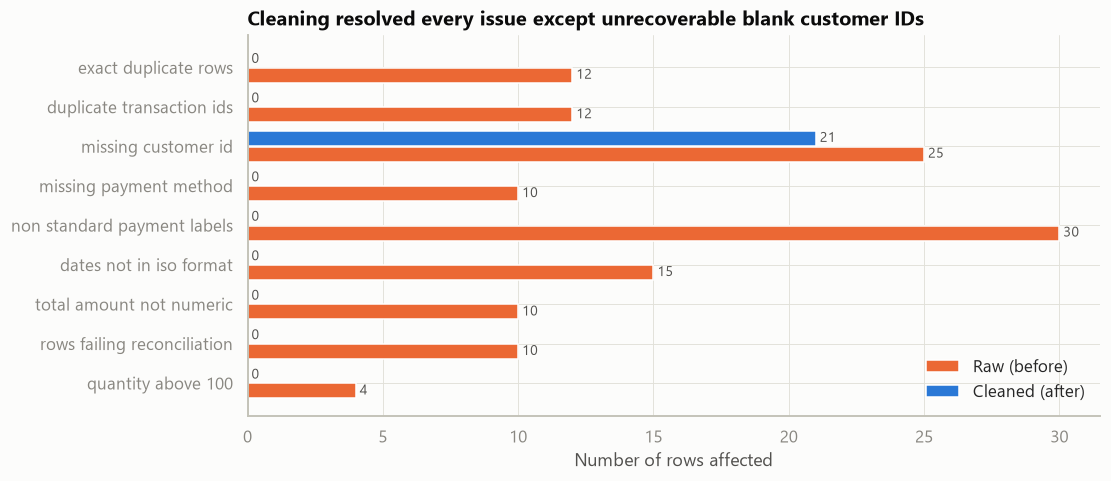

In [22]:
plot_df = comparison.drop(index=["rows"])
plot_df = plot_df[(plot_df["raw_before"] > 0)]

fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(plot_df))
ax.barh(y + 0.2, plot_df["raw_before"], height=0.38, color=style.SERIES[1], label="Raw (before)")
ax.barh(y - 0.2, plot_df["cleaned_after"], height=0.38, color=style.SERIES[0], label="Cleaned (after)")
ax.set_yticks(y, plot_df.index.str.replace("_", " "))
for yi, (b, a) in enumerate(zip(plot_df["raw_before"], plot_df["cleaned_after"])):
    ax.text(b, yi + 0.2, f" {b}", va="center", color=style.INK["secondary"], fontsize=9)
    ax.text(a, yi - 0.2, f" {a}", va="center", color=style.INK["secondary"], fontsize=9)
ax.invert_yaxis()
ax.set_title("Cleaning resolved every issue except unrecoverable blank customer IDs")
ax.set_xlabel("Number of rows affected")
ax.legend(loc="lower right")
style.save(fig, "m2_quality_before_after")
plt.show()

**Interpretation:** every problem has been resolved except **21 blank customer IDs**. These are deliberately kept as
flagged walk-in sales because there is no evidence to recover them. The 7 unrecoverable payment methods now hold the
explicit value `"Unknown"`, so they are no longer counted as blanks.

**Business implication:** management can trust revenue, profit and volume totals. Customer-level metrics will be
computed on the 99.3% of lines that have a customer ID, and that limitation is stated.

In [23]:
config.CLEANED_DIR.mkdir(parents=True, exist_ok=True)
config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
sales.to_csv(config.CLEANED_DIR / "sales_transactions.csv", index=False, date_format="%Y-%m-%d")
for name, df in dims.items():
    df.to_csv(config.CLEANED_DIR / f"{name}.csv", index=False, date_format="%Y-%m-%d")
analytical.to_csv(config.PROCESSED_DIR / "sales_analytical.csv", index=False, date_format="%Y-%m-%d")
print("Saved:", sorted(p.name for p in config.CLEANED_DIR.glob("*.csv")),
      "+ processed/sales_analytical.csv")

# The scripted pipeline must give exactly the same result as this notebook
from src.preprocessing.pipeline import run
pipeline_result = run()
pd.testing.assert_frame_equal(pipeline_result["sales"].reset_index(drop=True), sales.reset_index(drop=True))
print("Notebook and src/preprocessing/pipeline.py produce identical cleaned sales.")

Saved: ['calendar.csv', 'customers.csv', 'products.csv', 'promotions.csv', 'sales_transactions.csv', 'stores.csv'] + processed/sales_analytical.csv


Notebook and src/preprocessing/pipeline.py produce identical cleaned sales.


## 12. Audit against the injection log

Only now do we open `docs/dq_injection_log.csv`, which lists every problem deliberately injected in Milestone 1,
to check whether cleaning caught them all. As a stricter check, we also compare the cleaned table **cell by cell**
with the generator's clean version.

In [24]:
log = pd.read_csv(config.DOCS_DIR / "dq_injection_log.csv")
cleaned_idx = sales.set_index("transaction_id")

def outcome(row):
    if row["table"] != "sales_transactions":
        return "fixed (dimension label standardised)"
    if row["issue_type"] == "duplicate_row":
        return "fixed (duplicate removed)"
    value = cleaned_idx.at[row["record_key"], row["column"]]
    original = row["original_value"]
    if row["column"] == "customer_id" and pd.isna(value):
        return "flagged (walk-in, unrecoverable)"
    if row["column"] == "payment_method" and value == "Unknown":
        return "flagged (Unknown, unrecoverable)"
    if row["column"] == "transaction_date":
        return "fixed" if value == pd.Timestamp(original) else "NOT FIXED"
    if row["column"] in ("total_amount", "unit_price", "quantity"):
        return "fixed" if abs(float(value) - float(original)) < 0.01 else "NOT FIXED"
    return "fixed" if str(value) == str(original) else "NOT FIXED"

log["outcome"] = log.apply(outcome, axis=1)
pd.crosstab(log["issue_type"], log["outcome"], margins=True)

outcome,fixed,fixed (dimension label standardised),fixed (duplicate removed),"flagged (Unknown, unrecoverable)","flagged (walk-in, unrecoverable)",All
issue_type,,,,,,
calculation_mismatch,6,0,0,0,0,6
duplicate_row,0,0,12,0,0,12
inconsistent_date_format,15,0,0,0,0,15
inconsistent_label,30,11,0,0,0,41
missing_value,7,0,0,7,21,35
numeric_stored_as_text,10,0,0,0,0,10
outlier_entry_error,4,0,0,0,0,4
price_typo,3,0,0,0,0,3
All,75,11,12,7,21,126


In [25]:
from src.data_generation.generate_data import generate_clean_dataset

truth = generate_clean_dataset()["sales_transactions"]
truth["transaction_date"] = pd.to_datetime(truth["transaction_date"])
comparable = [c for c in truth.columns if c in sales.columns]

mismatched_cells = {}
for col in comparable:
    a, b = sales[col].reset_index(drop=True), truth[col].reset_index(drop=True)
    if pd.api.types.is_float_dtype(a):
        same = ((a - b).abs() < 0.01) | (a.isna() & b.isna())
    else:
        same = (a == b) | (a.isna() & b.isna())
    mismatched_cells[col] = int((~same).sum())
pd.Series(mismatched_cells, name="cells differing from true clean data").to_frame().T

,transaction_id,order_id,transaction_date,transaction_time,customer_id,store_id,product_id,quantity,unit_price,unit_cost,discount_percentage,discount_amount,total_amount,profit,payment_method,promotion_id
cells differing from true clean data,0,0,0,0,21,0,0,0,0,0,0,0,0,0,7,0


**Audit result:** every injected issue was **detected**.
- All duplicates, date formats, text amounts, label variants, quantity errors, price typos and calculation mismatches
  were fixed back to their **exact original values**.
- The only cells that differ from the true data are the **21 customer IDs** and **7 payment methods** that had no
  evidence to recover them. Leaving them blank or "Unknown" is the correct, honest outcome.

## 13. Summary of cleaning decisions

| Issue | Rows | Decision | Reasoning |
|---|---|---|---|
| Exact duplicate rows | 12 | Removed | Receipts submitted twice; no conflicting IDs remained |
| Non-ISO dates (DD/MM/YYYY) | 15 | Parsed with an explicit format | Avoids day/month swaps from guessing |
| Totals stored as text | 10 | Stripped "KES" and commas, converted | Value is correct, format is wrong |
| Payment label variants | 30 | Mapped to 4 standard labels | Explicit, reviewable lookup |
| Missing payment method | 10 | 3 recovered from the same order; 7 set to "Unknown" | Recover with evidence, never guess |
| Missing customer ID | 25 | 4 recovered from the same order; 21 kept as flagged walk-ins | The sale is real; customer histories must not be corrupted |
| Quantity 999 | 4 | Restored from the receipt total | Total and quantity contradict; 999 is a keying error |
| Bulk purchases (60, 48) | 2 | **Kept** | Totals reconcile, so these are genuine |
| Unit price 10× shelf price | 3 | Replaced with the shelf price | No business reason for a 10× price |
| Total missing the discount | 6 | Recalculated | Promotion and discount are valid; the stored total is a bug |
| High-value lines (IQR outliers) | many | **Kept** | Real electronics and clothing sales; skew handled in analysis |
| Category, county and gender label variants | 11 | Standardized | Inconsistent master data |

**Output:** `data/cleaned/` (6 normalized tables, 2,988 sales lines), `data/processed/sales_analytical.csv`,
`reports/data_quality_before_after.csv`.